In [17]:
%load_ext autoreload
%autoreload 2

import cv2
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from deepface import DeepFace
from deepface.models.Detector import FacialAreaRegion
from tqdm.auto import tqdm

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [18]:
RESULTS_PATH = Path("../../results/collect/structure.parquet")
RESULTS = pd.read_parquet(RESULTS_PATH)
RESULTS

,top-1,top-5,top-10,frame-top-1,fold,frame_anonymization_method,frame_embedding_method,video_aggregation_method,video_embedding_method,identity_aggregation_method,pipeline
0,0.752306,0.865613,0.898551,0.625672,1,none,sface,none,None,none,frame
1,0.809122,0.891892,0.915541,0.666414,2,none,sface,none,None,none,frame
2,0.781885,0.870610,0.898336,0.654930,3,none,sface,none,None,none,frame
3,0.716733,0.836627,0.877470,0.626610,1,none,sface,none,None,pooling_mean,frame
4,0.766892,0.854730,0.881757,0.657236,2,none,sface,none,None,pooling_mean,frame
...,...,...,...,...,...,...,...,...,...,...,...
319,0.038851,0.092905,0.148649,0.038851,2,pixelation,arcface,consensus_beta1,None,pooling_mean,frame
320,0.051756,0.107209,0.127542,0.051756,3,pixelation,arcface,consensus_beta1,None,pooling_mean,frame
321,0.047431,0.090909,0.115942,0.047431,1,pixelation,arcface,consensus_beta1,None,consensus_beta1,frame
322,0.038851,0.092905,0.150338,0.038851,2,pixelation,arcface,consensus_beta1,None,consensus_beta1,frame


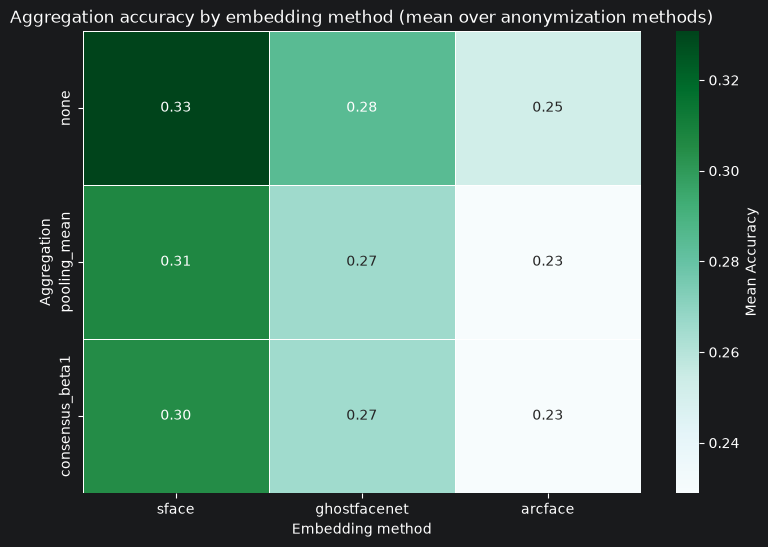

In [11]:
# Select all rows where the same aggregation method is used for both the video and identity. This collapses one dimension and simulates the previous results.
results = RESULTS[RESULTS["identity_aggregation_method"] == RESULTS["video_aggregation_method"]]

agg_order = (
    results.groupby("identity_aggregation_method")["top-1"].mean().sort_values(ascending=False).index
)
embedding_order = (
    results.groupby("frame_embedding_method")["top-1"].mean().sort_values(ascending=False).index
)

pivot_agg_embed = RESULTS.pivot_table(
    index="video_aggregation_method", columns="frame_embedding_method", values="top-1", aggfunc="mean"
).loc[agg_order, embedding_order]

plt.figure(figsize=(9, 6))
sns.heatmap(pivot_agg_embed, annot=True, fmt=".2f", cmap="BuGn", cbar_kws={"label": "Mean Accuracy"}, linewidths=0.5, linecolor="w")

plt.title("Aggregation accuracy by embedding method (mean over anonymization methods)")
plt.xlabel("Embedding method")
plt.ylabel("Aggregation")
plt.show()

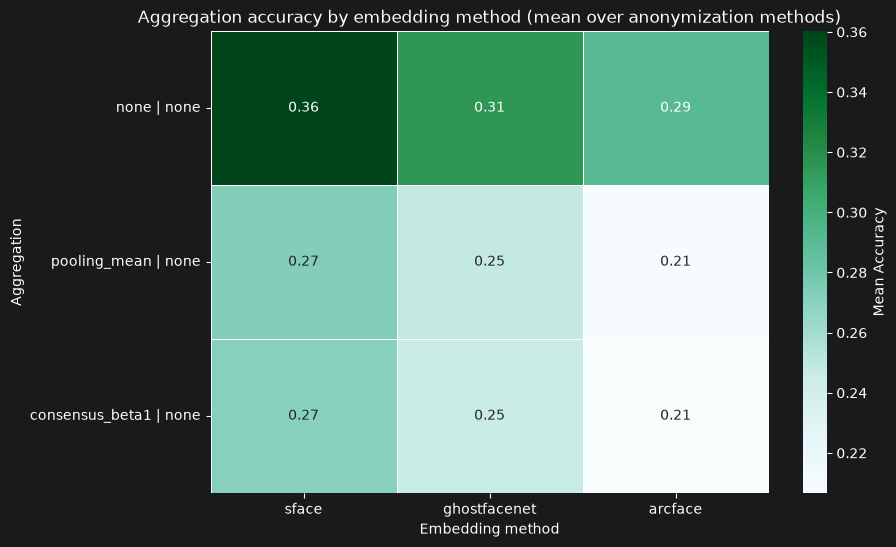

In [25]:
# Select all rows where the same aggregation method is used for both the video and identity. This collapses one dimension and simulates the previous results.

# TODO removes a lot of entries!
results["aggregation_method"] = RESULTS[["video_aggregation_method", "identity_aggregation_method"]].apply(lambda row: ' | '.join(row.values.astype(str)), axis=1)

agg_order = (
    results.groupby("aggregation_method")["top-1"].mean().sort_values(ascending=False).index
)
embedding_order = (
    results.groupby("frame_embedding_method")["top-1"].mean().sort_values(ascending=False).index
)

pivot_agg_embed = results.pivot_table(
    index="aggregation_method", columns="frame_embedding_method", values="top-1", aggfunc="mean"
).loc[agg_order, embedding_order]

plt.figure(figsize=(9, 6))
sns.heatmap(pivot_agg_embed, annot=True, fmt=".2f", cmap="BuGn", cbar_kws={"label": "Mean Accuracy"}, linewidths=0.5, linecolor="w")

plt.title("Aggregation accuracy by embedding method (mean over anonymization methods)")
plt.xlabel("Embedding method")
plt.ylabel("Aggregation")
plt.show()